### Import Library

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

### Memuat data siap pakai dari hasil Tahap 6

In [2]:
X_train, X_test, y_train, y_test = joblib.load('../dataset/step_06_ready_for_model.pkl')
print("Data berhasil dimuat! Ukuran X_train:", X_train.shape)

Data berhasil dimuat! Ukuran X_train: (3891, 12)


### Mencari Jumlah Pohon (n_estimators) Terbaik Berdasarkan R2 Score

In [6]:
n_trees = [50, 100, 150, 200]
r2_scores = []

for n in n_trees:
    rf_temp = RandomForestRegressor(n_estimators=n, random_state=42)
    rf_temp.fit(X_train, y_train)
    y_pred_temp = rf_temp.predict(X_test)
    r2_scores.append(r2_score(y_test, y_pred_temp))

best_n = n_trees[np.argmax(r2_scores)]
print(f"Jumlah n_estimators terbaik adalah: {best_n} dengan R2 Score: {max(r2_scores):.4f}")

Jumlah n_estimators terbaik adalah: 100 dengan R2 Score: 0.7474


### Visualisasi n_estimators vs R2 Score

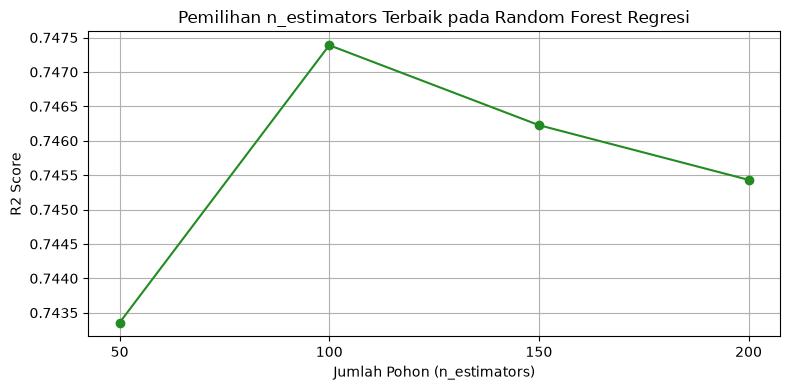

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(n_trees, r2_scores, marker='o', linestyle='-', color='forestgreen')
plt.title('Pemilihan n_estimators Terbaik pada Random Forest Regresi')
plt.xlabel('Jumlah Pohon (n_estimators)')
plt.ylabel('R2 Score')
plt.xticks(n_trees)
plt.grid(True)
plt.tight_layout()
plt.show()

### Melatih Model Random Forest Regresi Final

In [7]:
start_time = time.perf_counter()

rf = RandomForestRegressor(n_estimators=best_n, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

end_time = time.perf_counter()

waktu_rf = end_time - start_time

print("Model Berhasil Dibuat!")
print(f"Waktu Eksekusi Model Random Forest Regresi: {waktu_rf:.4f} detik")

Model Berhasil Dibuat!
Waktu Eksekusi Model Random Forest Regresi: 2.4283 detik


### Evaluasi

In [8]:
r2_rf   = r2_score(y_test, y_pred)
mae_rf  = mean_absolute_error(y_test, y_pred)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred))
mape_rf = mean_absolute_percentage_error(y_test, y_pred) * 100 # Dalam persen (%)

print("=== HASIL EVALUASI MODEL RANDOM FOREST REGRESI ===")
print(f"1. R2 Score       : {r2_rf:.4f} ({r2_rf*100:.2f}%)")
print(f"2. MAE            : Rp {mae_rf:,.2f}")
print(f"3. RMSE           : Rp {rmse_rf:,.2f}")
print(f"4. MAPE           : {mape_rf:.2f}%")
print(f"5. Waktu Eksekusi : {waktu_rf:.4f} detik")

=== HASIL EVALUASI MODEL RANDOM FOREST REGRESI ===
1. R2 Score       : 0.7474 (74.74%)
2. MAE            : Rp 464,213,361.39
3. RMSE           : Rp 658,414,530.18
4. MAPE           : 149.70%
5. Waktu Eksekusi : 2.4283 detik


### Tabel Perbandingan Harga Aktual dan Harga Prediksi

In [9]:
df_perbandingan_harga = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': y_pred
})

display(df_perbandingan_harga.head(10))

,Aktual,Prediksi
0,2400000000,2.280600e+09
1,3400000000,2.992325e+09
2,2270000000,2.626800e+09
3,2480000000,2.502363e+09
4,1400000000,1.998700e+09
5,1350000000,1.993200e+09
6,4600000000,4.479773e+09
7,1600000000,2.004650e+09
8,2100000000,3.048233e+09
9,2200000000,1.927828e+09


### Visualisasi Perbandingan Harga Aktual dan Prediksi

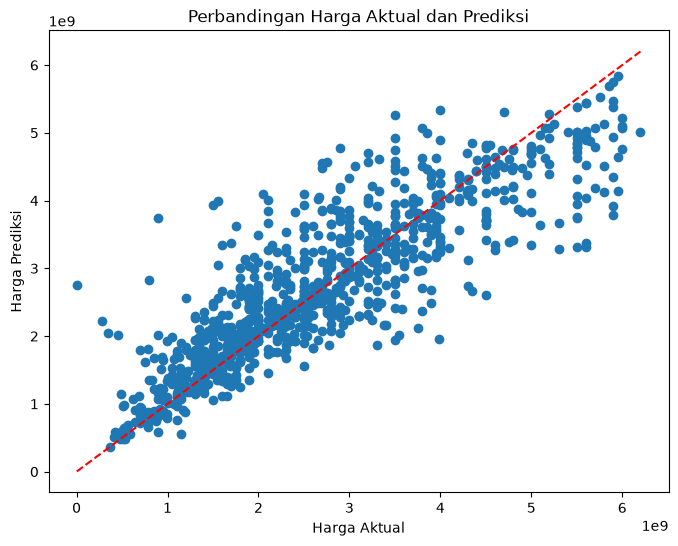

In [10]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Perbandingan Harga Aktual dan Prediksi')

plt.show()

### Analisis Feature Importance pada Random Forest

In [11]:
# Mengambil daftar nama kolom fitur dari step 5
df_step5 = joblib.load('../dataset/step_05_selected.pkl')
X_columns = df_step5.drop(columns=['price']).columns

feature_importance = pd.DataFrame({
    'Fitur': X_columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Fitur,Importance
11,total_area,0.641831
0,district,0.083174
1,city,0.047878
5,land_area,0.044207
8,building_ratio,0.035547
9,remaining_land,0.033445
6,building_area,0.027651
10,total_facilities,0.024309
7,total_rooms,0.018448
3,bath_rooms,0.016967


### Menyimpan Hasil Random Forest Regresi

In [12]:
hasil_rf_reg = {
    'Model': 'Random Forest',
    'R2': r2_rf,
    'MAE': mae_rf,
    'RMSE': rmse_rf,
    'MAPE (%)': mape_rf,
    'Waktu (Detik)': waktu_rf,
    'y_test': y_test,
    'y_pred': y_pred
}

joblib.dump(hasil_rf_reg, 'hasil_rf.pkl')
print("Hasil evaluasi Random Forest Regresi berhasil disimpan ke 'regresi_model/hasil_rf.pkl'!")

Hasil evaluasi Random Forest Regresi berhasil disimpan ke 'regresi_model/hasil_rf.pkl'!
